# 04 · Customer-value coverage under a contact budget

Historical demonstration on January 1, 2022. Budget and unit cost are illustrative. Covered purchase value does not measure incremental campaign revenue.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUN = Path(__import__("os").environ.get("AMAZON_CLV_RUN", str(ROOT / "runs" / "main")))
assert (RUN / "manifest.json").exists(), "Run python -m amazon_clv run first"
audit = json.loads((RUN / "data_audit.json").read_text())
manifest = json.loads((RUN / "manifest.json").read_text())
pd.set_option("display.max_columns", 20)
print("Source MD5:", audit["md5"], "| Model version:", manifest["run_version"])


Source MD5: 3549d72735b1211ab009ff0177b94bd9 | Model version: amazon-clv-1.0-6efb098a6e


In [2]:
from amazon_clv.marketing import capacity,compare_audiences,export_selection
pred = pd.read_parquet(RUN / "customer_predictions.parquet")
frame = pred.loc[pred.scoring_date.eq("2022-01-01") & pred.horizon.eq(90)].copy()
comparison,selection = compare_audiences(frame,budget=1000,contact_cost=1)
display(comparison)
display(selection.head(10))
print("Selected",len(selection),"accounts out of",len(frame))

,strategy,contacts,cost,actual_spending_covered,coverage_fraction,overlap_with_predicted
0,Predicted spending,1000,1000.0,1313621.52,0.533786,1.000
1,Historical spending,1000,1000.0,1309821.08,0.532241,0.870
2,Recency,1000,1000.0,941112.66,0.382418,0.469
3,Seeded random,1000,1000.0,500476.93,0.203367,0.199


,audience_rank,customer_id,scoring_date,recency_days,history_days,historical_score,spend_90,purchase_days_365,horizon,predicted_spending,raw_predicted_spending,coherence_adjusted,actual_spending,model_name,model_version,segment
3719,1,R_40engukXSxhrtF7,2022-01-01,1,1421,49258.78,18057.40,130.0,90,10269.567675,10269.567675,False,2268.57,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
3748,2,R_4ZKWBs8TstBB0Pv,2022-01-01,1,1454,18827.28,9871.45,61.0,90,6362.321705,6362.321705,False,1152.16,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
1600,3,R_2EglJpTWGEiwQYa,2022-01-01,2,1460,26116.87,7232.34,263.0,90,5983.171265,5983.171265,False,5811.57,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
2508,4,R_2z7rLZb69WuqDdf,2022-01-01,1,1456,19486.26,9079.56,177.0,90,5663.089038,5663.089038,False,13416.64,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
1274,5,R_24csoaO569P4Yzz,2022-01-01,1,1451,20557.88,4383.02,269.0,90,4795.573768,4795.573768,False,3724.39,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
625,6,R_1QtQEfi1VAWgRM0,2022-01-01,1,1459,22526.06,5925.51,186.0,90,4737.030025,4737.030025,False,5298.68,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
3474,7,R_3m3H4mwZ2snYFua,2022-01-01,3,1450,13814.80,4885.15,194.0,90,4602.118820,4602.118820,False,2223.44,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
3929,8,R_AKBlDprDMrv4M7v,2022-01-01,1,1460,25003.97,6480.95,215.0,90,4581.372274,4581.372274,False,6467.45,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
4567,9,R_cucdDIXhmDRBfZT,2022-01-01,1,1461,22876.90,5886.52,175.0,90,4465.884265,4465.884265,False,4617.22,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established
3853,10,R_8CXcySQawXPuJwJ,2022-01-01,2,1459,24182.69,4581.62,238.0,90,4353.863097,4353.863097,False,10957.14,hgb_0.05_15,amazon-clv-1.0-6efb098a6e,Established


Selected 1000 accounts out of 4991


## Check budget edge cases and exported identity
All strategies get equal capacity. A seeded random benchmark makes this demo reproducible. The exact displayed selection feeds the CSV download.

In [3]:
import io
exported = pd.read_csv(io.BytesIO(export_selection(selection)))
assert exported.customer_id.tolist() == selection.customer_id.tolist()
assert capacity(0,1,len(frame)) == 0
assert capacity(10**9,1,len(frame)) == len(frame)
assert capacity(.3,.1,len(frame)) == 3
assert compare_audiences(frame,0,1)[0].actual_spending_covered.eq(0).all()
for cost in [0,-1,float("inf")]:
    try:
        capacity(100,cost,len(frame))
        raise AssertionError("Invalid cost should fail")
    except ValueError:
        pass
print("PASS: zero/oversized budgets, cost validation, cent arithmetic, exact export")

PASS: zero/oversized budgets, cost validation, cent arithmetic, exact export


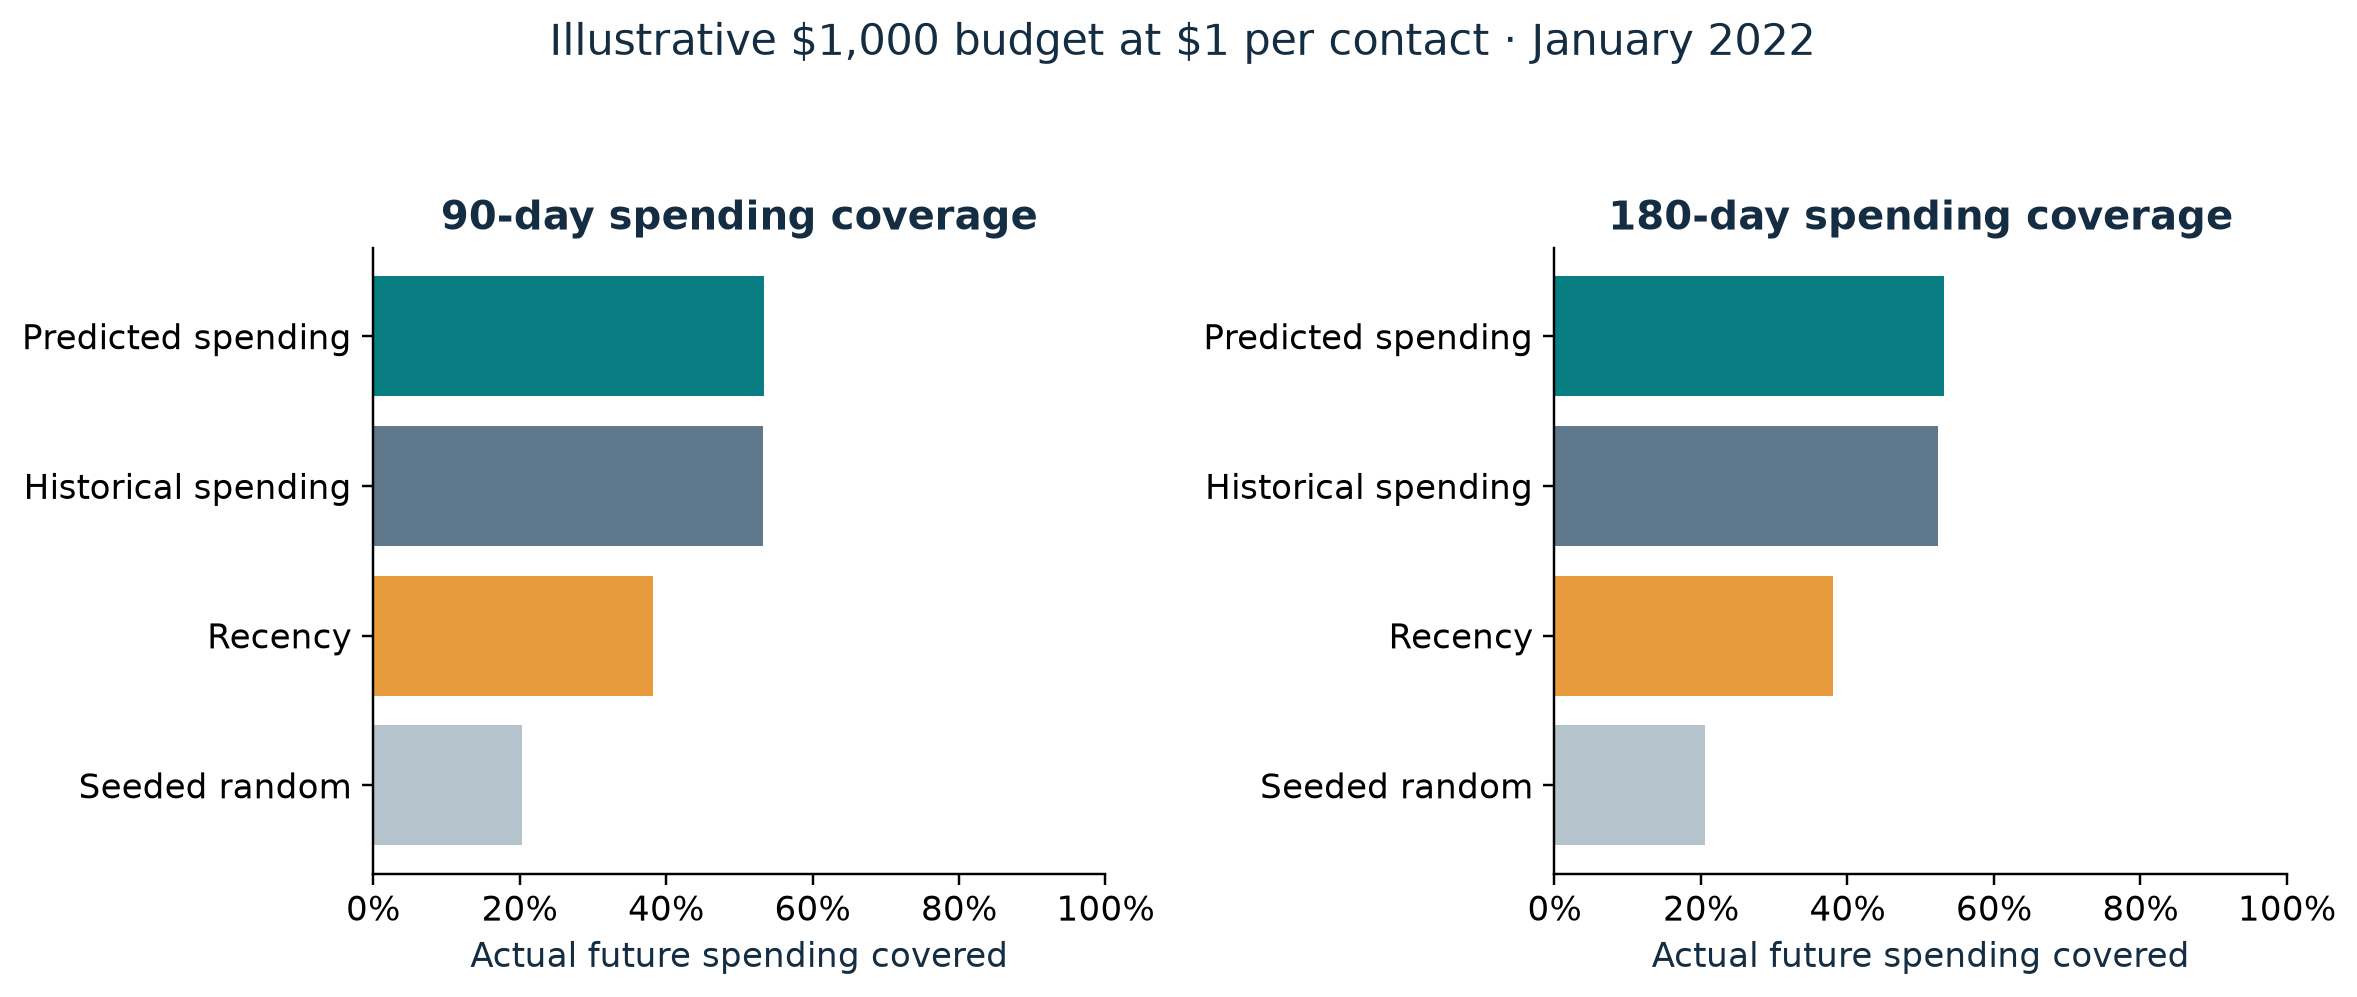

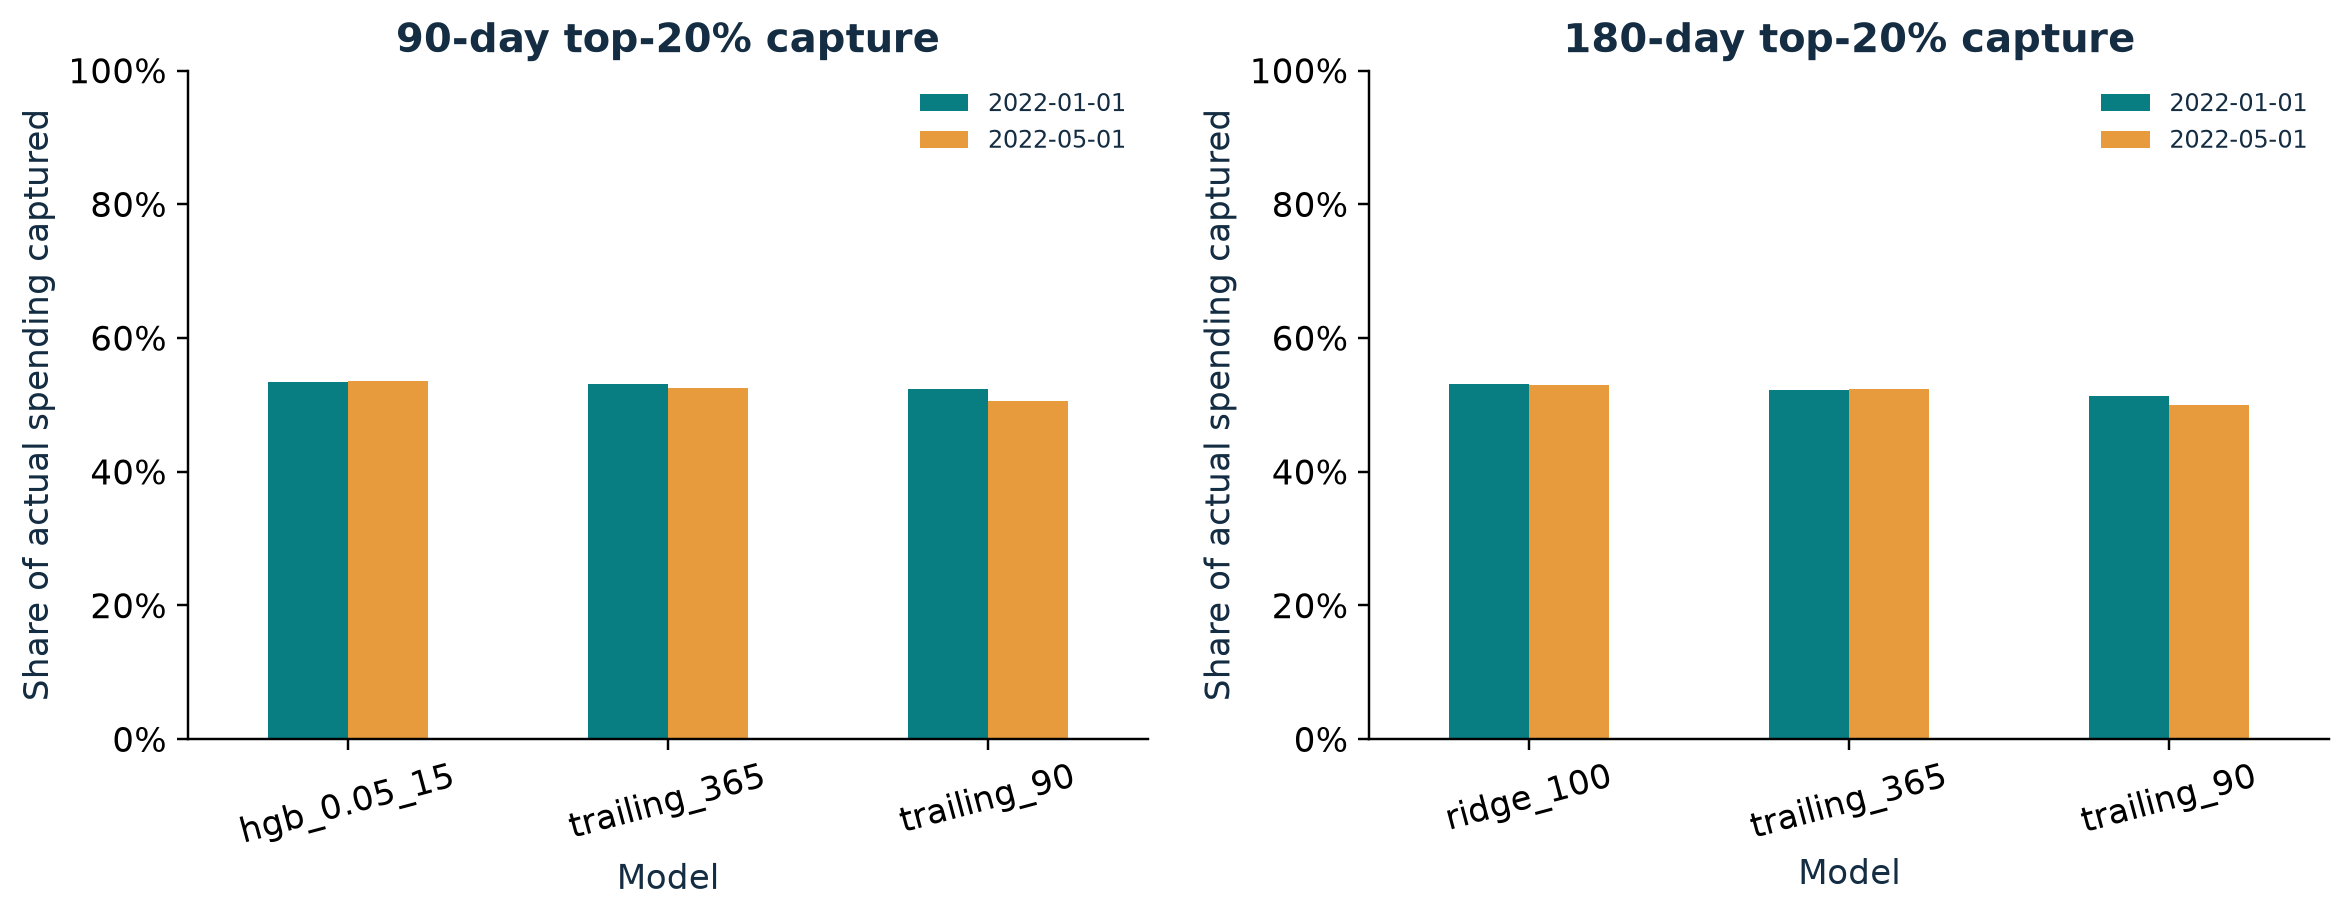

,strategy,contacts,cost,actual_spending_covered,coverage_fraction,overlap_with_predicted,budget
0,Predicted spending,0,0.0,0.00,0.000000,0.0000,0
1,Historical spending,0,0.0,0.00,0.000000,0.0000,0
2,Recency,0,0.0,0.00,0.000000,0.0000,0
3,Seeded random,0,0.0,0.00,0.000000,0.0000,0
4,Predicted spending,100,100.0,281812.15,0.114513,1.0000,100
5,Historical spending,100,100.0,272246.49,0.110626,0.6800,100
6,Recency,100,100.0,112900.91,0.045877,0.1500,100
7,Seeded random,100,100.0,54890.22,0.022304,0.0200,100
8,Predicted spending,500,500.0,866581.97,0.352133,1.0000,500
9,Historical spending,500,500.0,859449.91,0.349235,0.8460,500


In [4]:
display(Image(filename=str(RUN / "charts" / "marketing_coverage.png")))
display(Image(filename=str(RUN / "charts" / "ranking_capture.png")))
rows=[]
for budget in [0,100,500,1000,2500,10000]:
    c,_=compare_audiences(frame,budget,1)
    rows.append(c.assign(budget=budget))
display(pd.concat(rows,ignore_index=True))

## What a marketer can claim
At this historical date, the selection covers a measured fraction of future recorded spending within an assumed uniform contact budget. Audience overlap shows how much selection changes relative to existing heuristics. It does not show how spending would change after contact. Randomized treatments, observed response, offer/contact costs, and contribution margins are required for causal marketing ROI or profit optimization. Shared accounts and the retrospective cohort limit extrapolation. Read INTERVIEW_GUIDE.md for a full technical explanation.